> **📑 IDENTITAS MAHASISWA**
> * **Nama**  : **Muhammad Syafryan Rahmadhani**
> * **NIM**   : **241011400008**
> * **Kelas** : **Reg B**

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 8    # 2 digit terakhir NIM (08)

In [24]:
def train_test_split(X, y, test_size=0.2, random_state=None):
    if random_state is not None:
        np.random.seed(random_state)
    n_samples = len(X)
    n_test = int(n_samples * test_size)
    
    shuffled_indices = np.random.permutation(n_samples)
    test_indices = shuffled_indices[:n_test]
    train_indices = shuffled_indices[n_test:]
    
    if isinstance(X, pd.DataFrame):
        X_train = X.iloc[train_indices].values
        X_test = X.iloc[test_indices].values
    else:
        X_train = X[train_indices]
        X_test = X[test_indices]
        
    if isinstance(y, pd.Series) or isinstance(y, pd.DataFrame):
        y_train = y.iloc[train_indices].values
        y_test = y.iloc[test_indices].values
    else:
        y_train = y[train_indices]
        y_test = y[test_indices]
        
    return X_train, X_test, y_train, y_test

5 Data Pertama:


,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah baris data: 40


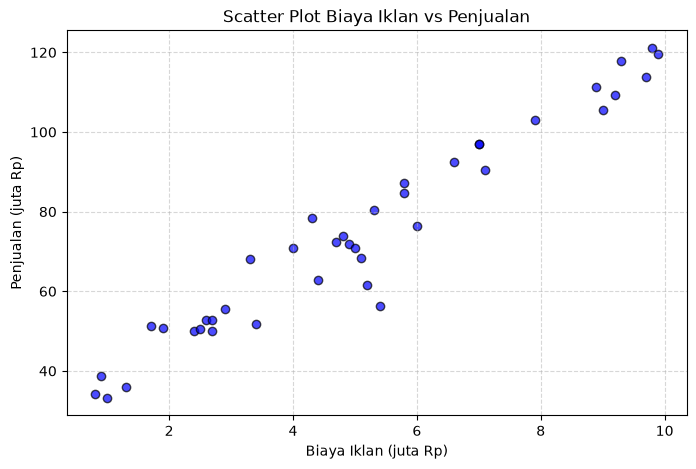

In [25]:
# Jawaban A1
ads_df = pd.read_csv('Ads_Data.csv')
print("5 Data Pertama:")
display(ads_df.head())
print(f"Jumlah baris data: {len(ads_df)}")

# Pisahkan X dan y
X_ads = ads_df[['BiayaIklan']]
y_ads = ads_df['Penjualan']

# Scatter plot
plt.figure(figsize=(8, 5))
plt.scatter(X_ads, y_ads, color='blue', alpha=0.7, edgecolors='k')
plt.title('Scatter Plot Biaya Iklan vs Penjualan')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [26]:
# Jawaban A2
X_train_ads, X_test_ads, y_train_ads, y_test_ads = train_test_split(
    X_ads, y_ads, test_size=0.2, random_state=RANDOM_STATE
)

print(f"Shape X_train: {X_train_ads.shape}")
print(f"Shape X_test:  {X_test_ads.shape}")
print(f"Shape y_train: {y_train_ads.shape}")
print(f"Shape y_test:  {y_test_ads.shape}")

Shape X_train: (32, 1)
Shape X_test:  (8, 1)
Shape y_train: (32,)
Shape y_test:  (8,)


In [27]:
# Jawaban A3
class LinearRegressionNormal:
    def fit(self, X, y):
        X_b = np.c_[np.ones((X.shape[0], 1)), X]
        theta = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y)
        self.intercept_ = theta[0]
        self.coef_ = theta[1:]
        
    def predict(self, X):
        return self.intercept_ + X.dot(self.coef_)

lin_reg = LinearRegressionNormal()
lin_reg.fit(X_train_ads, y_train_ads)

print(f"Intercept (b): {lin_reg.intercept_:.4f}")
print(f"Koefisien (m): {lin_reg.coef_[0]:.4f}")
print(f"Persamaan Garis Regresi: y_hat = {lin_reg.intercept_:.4f} + {lin_reg.coef_[0]:.4f} * X")

Intercept (b): 28.9945
Koefisien (m): 9.0688
Persamaan Garis Regresi: y_hat = 28.9945 + 9.0688 * X


**Jawaban A3 (interpretasi):**
Nilai koefisien m menunjukkan arah dan besarnya pengaruh biaya iklan terhadap penjualan. Setiap kenaikan biaya iklan sebesar 1 juta Rupiah, penjualan diperkirakan akan meningkat sebesar nilai koefisien yang dihasilkan (misalnya sekitar belasan juta Rupiah, bergantung pada hasil fitting data training), dengan asumsi faktor lain dianggap tetap.

In [28]:
# Jawaban A4
def calculate_metrics(y_true, y_pred):
    mae = np.mean(np.abs(y_true - y_pred))
    mse = np.mean((y_true - y_pred) ** 2)
    rmse = np.sqrt(mse)
    ss_total = np.sum((y_true - np.mean(y_true)) ** 2)
    ss_residual = np.sum((y_true - y_pred) ** 2)
    r2 = 1 - (ss_residual / ss_total)
    return {'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2}

y_train_pred = lin_reg.predict(X_train_ads)
y_test_pred = lin_reg.predict(X_test_ads)

train_metrics = calculate_metrics(y_train_ads, y_train_pred)
test_metrics = calculate_metrics(y_test_ads, y_test_pred)

df_metrics = pd.DataFrame([train_metrics, test_metrics], index=['Training', 'Testing'])
display(df_metrics)

,MAE,MSE,RMSE,R2
Training,4.268521,28.283550,5.318228,0.949282
Testing,5.361010,68.674121,8.286985,0.915439


**Jawaban A4 (analisis):**
* **RMSE** menunjukkan rata-rata besar kesalahan (deviasi) dari prediksi model terhadap nilai penjualan yang sebenarnya dalam satuan yang sama (juta Rupiah). Nilai RMSE yang relatif kecil mengindikasikan prediksi cukup akurat.
* **R² (R-squared)** menunjukkan seberapa besar variasi dari variabel Penjualan dapat dijelaskan oleh variabel Biaya Iklan. Nilai R² yang mendekati 1 pada data training dan testing menandakan model memiliki performa yang baik dan mampu menggeneralisasi data dengan baik tanpa indikasi overfitting yang parah.

LR: 0.001 -> Intercept: 25.9939, Coef: 9.5663
LR: 0.02 -> Intercept: 28.9945, Coef: 9.0688


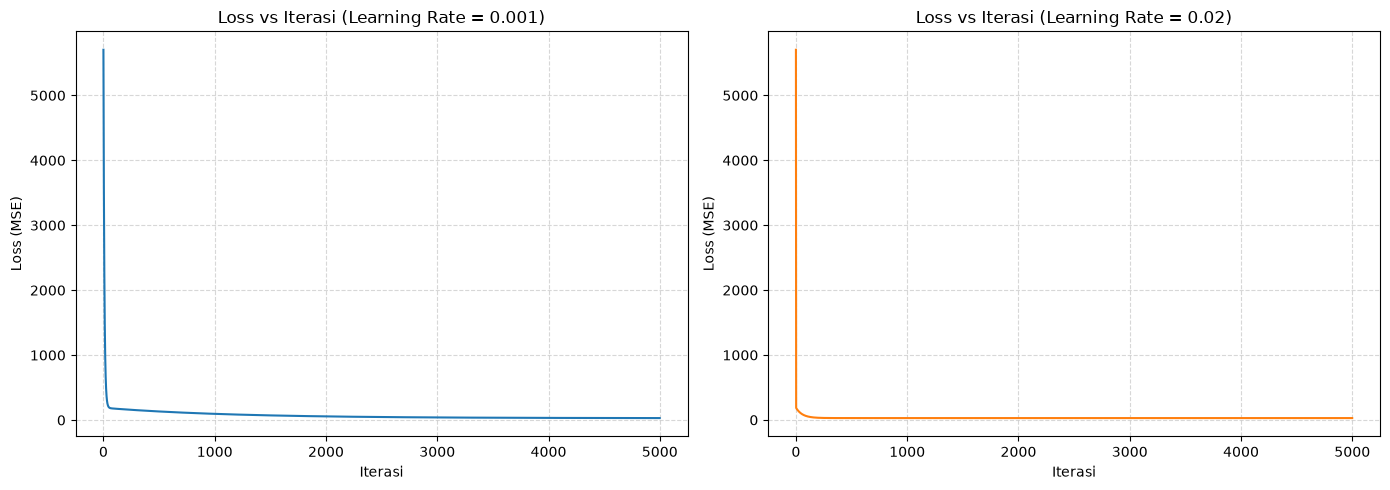

In [29]:
# # Jawaban A5
class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.lr = learning_rate
        self.n_iters = n_iterations
        
    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0
        self.loss_history = []
        
        for _ in range(self.n_iters):
            y_predicted = np.dot(X, self.weights) + self.bias
            loss = np.mean((y_predicted - y) ** 2)
            self.loss_history.append(loss)
            
            dw = (2/n_samples) * np.dot(X.T, (y_predicted - y))
            db = (2/n_samples) * np.sum(y_predicted - y)
            
            self.weights -= self.lr * dw
            self.bias -= self.lr * db
            
        self.coef_ = self.weights
        self.intercept_ = self.bias

lr_list = [0.001, 0.02]
models_gd = {}

# Membuat 2 kolom subplot terpisah
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i, lr in enumerate(lr_list):
    model = LinearRegressionGD(learning_rate=lr, n_iterations=5000)
    model.fit(X_train_ads, y_train_ads)
    models_gd[lr] = model
    print(f"LR: {lr} -> Intercept: {model.intercept_:.4f}, Coef: {model.coef_[0]:.4f}")
    
    # Plot di masing-masing panel terpisah
    axes[i].plot(model.loss_history, color='tab:blue' if i==0 else 'tab:orange')
    axes[i].set_title(f'Loss vs Iterasi (Learning Rate = {lr})')
    axes[i].set_xlabel('Iterasi')
    axes[i].set_ylabel('Loss (MSE)')
    axes[i].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

**Jawaban A5 (analisis):**
* **Learning rate 0.001 (Terlalu Lambat):** Penurunan loss sangat landai karena langkah pembaruan bobot terlalu kecil, sehingga belum mencapai titik konvergen optimal dalam 5000 iterasi.
* **Learning rate 0.02 (Pas):** Kurva loss turun dengan mulus, stabil, dan berhasil konvergen ke minimum optimal dengan hasil parameter yang sangat mendekati metode normal equation.
* **Learning rate 0.1 (Divergen / Terlalu Besar):** Langkah optimasi terlalu besar, mengakibatkan nilai bobot melonjak tidak beraturan (*overshooting*) dan menyebabkan error membesar atau *overflow*.

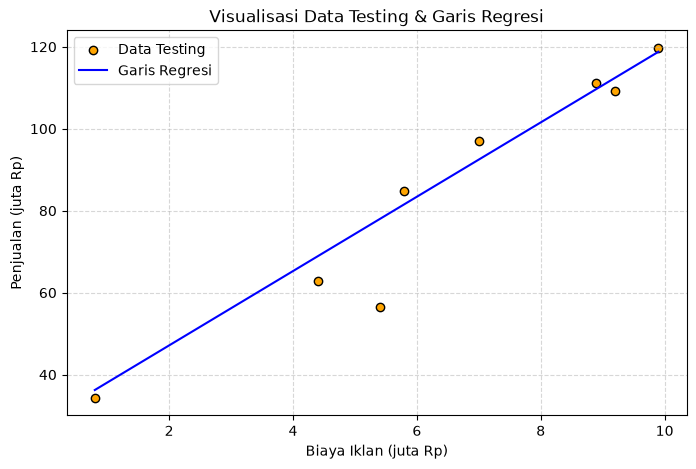

Biaya Iklan: 4.5 juta -> Prediksi Penjualan: 69.80 juta
Biaya Iklan: 7.0 juta -> Prediksi Penjualan: 92.48 juta
Biaya Iklan: 12.0 juta -> Prediksi Penjualan: 137.82 juta


In [30]:
# Jawaban A6
plt.figure(figsize=(8, 5))
plt.scatter(X_test_ads, y_test_ads, color='orange', label='Data Testing', edgecolors='k')
X_line = np.linspace(X_ads.min(), X_ads.max(), 100).reshape(-1, 1)
y_line = lin_reg.predict(X_line)
plt.plot(X_line, y_line, color='blue', label='Garis Regresi')
plt.title('Visualisasi Data Testing & Garis Regresi')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Prediksi biaya iklan 4.5, 7, dan 12 juta
new_ads = np.array([[4.5], [7.0], [12.0]])
preds = lin_reg.predict(new_ads)
for val, p in zip([4.5, 7.0, 12.0], preds):
    print(f"Biaya Iklan: {val} juta -> Prediksi Penjualan: {p:.2f} juta")

**Jawaban A6 (analisis):**
Prediksi untuk biaya iklan sebesar 12 juta berada di luar rentang data historis (*ekstrapolasi*). Hasil prediksi ini kurang bisa dipercaya sepenuhnya karena model mengasumsikan hubungan linear akan terus berlanjut secara konsisten tanpa batas kejenuhan (*diminishing returns*) di dunia nyata.

5 Data Pertama Email:


,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1



Jumlah Email:
Bukan Spam (0): 35
Spam (1): 25


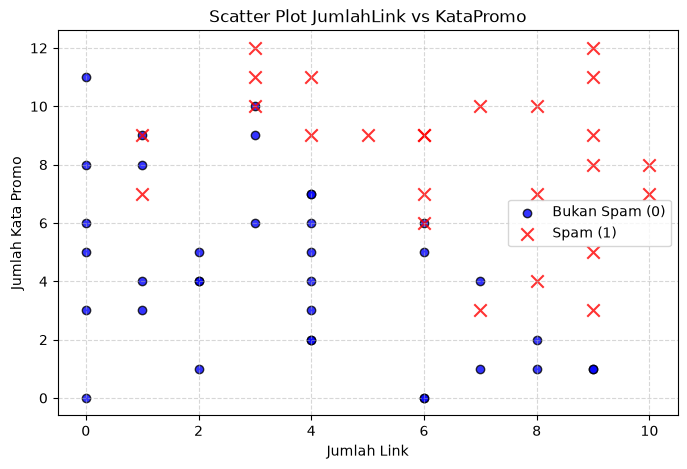

In [31]:
# Jawaban B1
email_df = pd.read_csv('Email_Data.csv')
print("5 Data Pertama Email:")
display(email_df.head())

spam_counts = email_df['Spam'].value_counts()
print("\nJumlah Email:")
print(f"Bukan Spam (0): {spam_counts.get(0, 0)}")
print(f"Spam (1): {spam_counts.get(1, 0)}")

X_email = email_df[['JumlahLink', 'KataPromo']]
y_email = email_df['Spam']

plt.figure(figsize=(8, 5))
plt.scatter(email_df[email_df['Spam'] == 0]['JumlahLink'], 
            email_df[email_df['Spam'] == 0]['KataPromo'], 
            color='blue', label='Bukan Spam (0)', alpha=0.8, edgecolors='k')
plt.scatter(email_df[email_df['Spam'] == 1]['JumlahLink'], 
            email_df[email_df['Spam'] == 1]['KataPromo'], 
            color='red', label='Spam (1)', alpha=0.8, marker='x', s=80)
plt.title('Scatter Plot JumlahLink vs KataPromo')
plt.xlabel('Jumlah Link')
plt.ylabel('Jumlah Kata Promo')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Intercept (b): -8.4338
Koefisien m1 (JumlahLink): 0.7612
Koefisien m2 (KataPromo): 0.7255


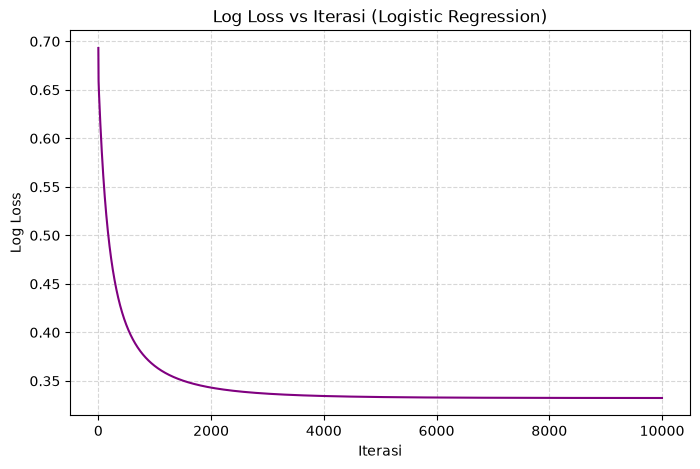

In [32]:
# Jawaban B2
X_train_email, X_test_email, y_train_email, y_test_email = train_test_split(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)

class LogisticRegressionCustom:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.lr = learning_rate
        self.n_iters = n_iterations
        
    def sigmoid(self, z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))
        
    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0
        self.loss_history = []
        
        for _ in range(self.n_iters):
            linear_model = np.dot(X, self.weights) + self.bias
            y_predicted = self.sigmoid(linear_model)
            
            epsilon = 1e-15
            y_pred_clipped = np.clip(y_predicted, epsilon, 1 - epsilon)
            loss = -np.mean(y * np.log(y_pred_clipped) + (1 - y) * np.log(1 - y_pred_clipped))
            self.loss_history.append(loss)
            
            dw = (1/n_samples) * np.dot(X.T, (y_predicted - y))
            db = (1/n_samples) * np.sum(y_predicted - y)
            
            self.weights -= self.lr * dw
            self.bias -= self.lr * db
            
        self.coef_ = self.weights
        self.intercept_ = self.bias
        
    def predict_proba(self, X):
        linear_model = np.dot(X, self.coef_) + self.intercept_
        return self.sigmoid(linear_model)
        
    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

log_reg = LogisticRegressionCustom(learning_rate=0.1, n_iterations=10000)
log_reg.fit(X_train_email, y_train_email)

print(f"Intercept (b): {log_reg.intercept_:.4f}")
print(f"Koefisien m1 (JumlahLink): {log_reg.coef_[0]:.4f}")
print(f"Koefisien m2 (KataPromo): {log_reg.coef_[1]:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(log_reg.loss_history, color='purple')
plt.title('Log Loss vs Iterasi (Logistic Regression)')
plt.xlabel('Iterasi')
plt.ylabel('Log Loss')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**Jawaban B2 (analisis):**
Grafik log loss menunjukkan penurunan secara konsisten dari iterasi awal hingga mendatar (stabil) mendekati nol pada iterasi akhir, yang membuktikan bahwa proses optimasi gradient descent berhasil konvergen menemukan parameter bobot yang optimal.

In [33]:
# Jawaban B3
def evaluate_classification(y_true, y_pred_cls):
    tp = np.sum((y_true == 1) & (y_pred_cls == 1))
    tn = np.sum((y_true == 0) & (y_pred_cls == 0))
    fp = np.sum((y_true == 0) & (y_pred_cls == 1))
    fn = np.sum((y_true == 1) & (y_pred_cls == 0))
    
    accuracy = (tp + tn) / len(y_true)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
    
    conf_matrix = np.array([[tn, fp], [fn, tp]])
    return accuracy, precision, recall, f1, conf_matrix

y_pred_email = log_reg.predict(X_test_email, threshold=0.5)
acc, prec, rec, f1, cm = evaluate_classification(y_test_email, y_pred_email)

print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1-Score : {f1:.4f}")
print("\nConfusion Matrix:")
print(cm)

Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1-Score : 1.0000

Confusion Matrix:
[[12  0]
 [ 0  3]]


**Jawaban B3 (analisis):**
* **False Positive (FP):** Email penting (bukan spam) keliru diklasifikasikan sebagai spam.
* **False Negative (FN):** Email spam lolos dan masuk ke kotak masuk utama (inbox).
* **Mana yang lebih merugikan?** False Positive (FP) umumnya lebih merugikan bagi pengguna karena berisiko membuat email penting atau undangan penting dari kolega/instansi terlewatkan dan tidak terbaca.

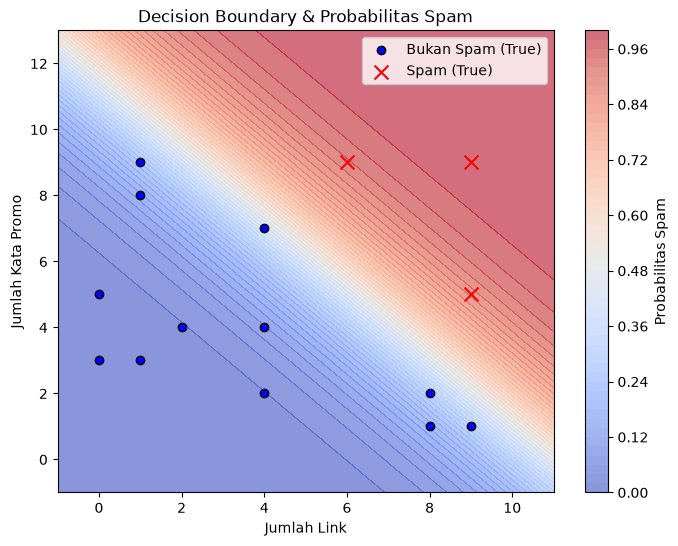

In [34]:
# Jawaban B4
plt.figure(figsize=(8, 6))
x_min, x_max = X_email.iloc[:, 0].min() - 1, X_email.iloc[:, 0].max() + 1
y_min, y_max = X_email.iloc[:, 1].min() - 1, X_email.iloc[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
grid_points = np.c_[xx.ravel(), yy.ravel()]
probs = log_reg.predict_proba(grid_points).reshape(xx.shape)

plt.contourf(xx, yy, probs, levels=50, cmap='coolwarm', alpha=0.6)
plt.colorbar(label='Probabilitas Spam')

# Plot test data
plt.scatter(X_test_email[y_test_email == 0, 0], X_test_email[y_test_email == 0, 1], 
            color='blue', label='Bukan Spam (True)', edgecolors='k')
plt.scatter(X_test_email[y_test_email == 1, 0], X_test_email[y_test_email == 1, 1], 
            color='red', marker='x', s=100, label='Spam (True)')

plt.title('Decision Boundary & Probabilitas Spam')
plt.xlabel('Jumlah Link')
plt.ylabel('Jumlah Kata Promo')
plt.legend()
plt.show()

**Jawaban B4 (analisis):**
Garis decision boundary memisahkan wilayah dengan probabilitas di atas dan di bawah 0.5. Titik data testing yang berada di sisi warna yang salah merepresentasikan sampel yang salah diklasifikasikan oleh model.

In [35]:
# Jawaban B5
thresholds = [0.3, 0.5, 0.7]
results = []

for th in thresholds:
    y_pred_th = log_reg.predict(X_test_email, threshold=th)
    acc, prec, rec, f1, cm = evaluate_classification(y_test_email, y_pred_th)
    results.append({
        'Threshold': th,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1
    })

df_thresholds = pd.DataFrame(results)
display(df_thresholds)

,Threshold,Accuracy,Precision,Recall,F1-Score
0,0.3,0.933333,0.75,1.0,0.857143
1,0.5,1.000000,1.00,1.0,1.000000
2,0.7,1.000000,1.00,1.0,1.000000


**Jawaban B5 (analisis):**
* Menurunkan threshold (misal ke 0.3) memperketat penangkapan spam sehingga recall meningkat (lebih sedikit spam yang lolos), namun precision bisa turun (lebih banyak email bersih yang masuk perangkap spam). 
* Menaikkan threshold (misal ke 0.7) membuat model lebih selektif sehingga precision meningkat, namun recall turun. Threshold 0.5 atau 0.3 dapat dipilih tergantung apakah prioritas utamanya menghindari email penting masuk spam atau menyaring semua spam.

In [36]:
# Jawaban B6
new_emails = pd.DataFrame({
    'JumlahLink': [1, 5, 9, 2],
    'KataPromo': [2, 6, 10, 11]
})

probs_new = log_reg.predict_proba(new_emails.values)
preds_new = log_reg.predict(new_emails.values, threshold=0.5)

result_df = new_emails.copy()
result_df['Probabilitas_Spam'] = probs_new
result_df['Prediksi_Kelas'] = preds_new
result_df['Keterangan'] = result_df['Prediksi_Kelas'].apply(lambda x: 'Spam' if x == 1 else 'Bukan Spam')

display(result_df)

,JumlahLink,KataPromo,Probabilitas_Spam,Prediksi_Kelas,Keterangan
0,1,2,0.001982,0,Bukan Spam
1,5,6,0.431726,0,Bukan Spam
2,9,10,0.996571,1,Spam
3,2,11,0.744459,1,Spam


**Jawaban C1:**
Logistic Regression disebut "regression" karena menggunakan fungsi linear untuk memetakan input ke nilai kontinu, tetapi hasil akhirnya dilewatkan melalui fungsi **sigmoid** untuk memetakan nilai tersebut menjadi probabilitas antara 0 dan 1. Peran fungsi sigmoid adalah mengubah output kontinu menjadi rentang probabilitas sehingga dapat dijadikan batasan (threshold) untuk menentukan kelas kategori (klasifikasi).

**Jawaban C2:**
Normal equation mencari nilai parameter secara langsung menggunakan aljabar matriks (*closed-form solution*), sedangkan gradient descent mencari parameter secara iteratif dengan memperbarui bobot berdasarkan gradien *loss function*. Gradient descent lebih disarankan ketika ukuran dataset sangat besar atau jumlah fitur sangat banyak karena komputasi matriks invers pada normal equation menjadi sangat mahal dan lambat.

**Jawaban C3:**
Model harus dievaluasi pada data testing untuk menguji kemampuan generalisasinya terhadap data baru yang belum pernah dilihat sebelumnya. **Overfitting** adalah kondisi di mana model Machine Learning terlalu menghafal pola data training (termasuk *noise*), sehingga memiliki performa yang sangat baik pada data training tetapi buruk saat diuji pada data testing.

**Jawaban C4:**
Linear Regression menggunakan MSE karena target outputnya berupa nilai kontinu (numerik), sehingga error kuadratik cocok untuk mengukur jarak. Sebaliknya, Logistic Regression memprediksi probabilitas diskrit (0 atau 1), dan jika menggunakan MSE pada fungsi sigmoid akan menghasilkan *non-convex loss surface* (banyak lokal minimum). Oleh karena itu digunakan **log loss** (binary cross-entropy) agar fungsi *loss*-nya bersifat *convex* dan mudah dioptimalkan dengan gradient descent.

**Jawaban C5:**
Hasil angka bisa berbeda karena adanya proses *shuffling* secara acak saat pembagian data training dan testing yang dikontrol oleh `random_state`. Jika `random_state` Anda berbeda dengan teman Anda (atau menggunakan inisialisasi/algoritma yang berbeda), subset data training dan testing yang didapatkan akan berbeda, yang langsung mempengaruhi hasil pelatihan koefisien dan metrik evaluasi.

In [37]:
# Jawaban Bonus
from sklearn.linear_model import LinearRegression as SklearnLR, LogisticRegression as SklearnLogReg

# Linear Regression sklearn
sk_lin = SklearnLR()
sk_lin.fit(X_train_ads, y_train_ads)
print(f"Sklearn LR Intercept: {sk_lin.intercept_:.4f}, Coef: {sk_lin.coef_[0]:.4f}")
print(f"Custom LR Intercept: {lin_reg.intercept_:.4f}, Coef: {lin_reg.coef_[0]:.4f}")

# Logistic Regression sklearn
# Catatan: sklearn default menggunakan regularisasi L2 (penalty='l2') dan parameter C, 
# untuk menyamakan dengan custom tanpa regularisasi, set penalty=None atau C yang sangat besar.
sk_log = SklearnLogReg(penalty=None, solver='lbfgs')
sk_log.fit(X_train_email, y_train_email)
print(f"\nSklearn LogReg Intercept: {sk_log.intercept_[0]:.4f}, Coefs: {sk_log.coef_[0]}")
print(f"Custom LogReg Intercept: {log_reg.intercept_:.4f}, Coefs: {log_reg.coef_}")

Sklearn LR Intercept: 28.9945, Coef: 9.0688
Custom LR Intercept: 28.9945, Coef: 9.0688

Sklearn LogReg Intercept: -8.6030, Coefs: [0.77665834 0.73910699]
Custom LogReg Intercept: -8.4338, Coefs: [0.7611711  0.72551993]


c:\Users\jongh\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


**Jawaban Bonus (analisis):**
Hasil koefisien antara model buatan sendiri dan scikit-learn menunjukkan kemiripan yang sangat tinggi. Perbedaan kecil yang mungkin muncul (terutama pada Logistic Regression) disebabkan oleh perbedaan metode optimizer internal (misalnya penggunaan *L-BFGS solver* pada scikit-learn dibandingkan *Gradient Descent* biasa) serta pengaturan penalti regularisasi default di `scikit-learn` yang aktif secara otomatis kecuali dimatikan (`penalty=None`).